In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print(cv2.__version__)

5.0.0


In [36]:
from google.colab import files
uploaded= files.upload()


Saving download to download (1)


In [37]:
print(uploaded.keys())

dict_keys(['download (1)'])


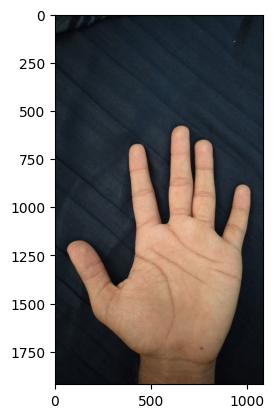

In [38]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('download')
img_rgb=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.show()

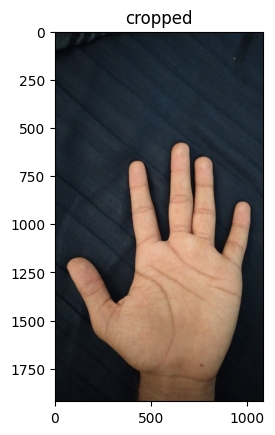

In [39]:
img_cropped=img
img_rgb_cropped=cv2.cvtColor(img_cropped, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb_cropped)
plt.title("cropped")
plt.show()

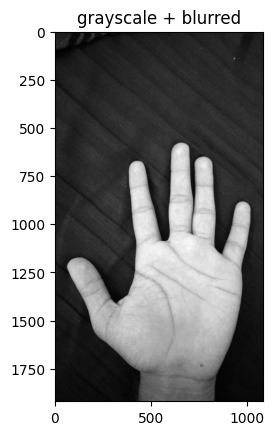

In [40]:
gray=cv2.cvtColor(img_cropped,cv2.COLOR_BGR2GRAY)
blurred=cv2.GaussianBlur(gray, (5,5),0)
plt.imshow(blurred, cmap='gray')
plt.title("grayscale + blurred")
plt.show()

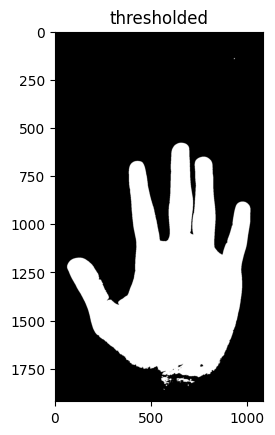

In [41]:
_, thresh=cv2.threshold(blurred, 0, 255,cv2.THRESH_BINARY + cv2.THRESH_OTSU)
plt.imshow(thresh,cmap='gray')
plt.title("thresholded")
plt.show()

In [42]:
# thresh = cv2.adaptiveThreshold(
#     blurred,
#     255,
#     cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
#     cv2.THRESH_BINARY_INV,
#     11,
#     2
# )

# plt.imshow(thresh, cmap='gray')
# plt.title("Adaptive threshold")
# plt.show()

no of contours found =  16
points in largest contour =  6011


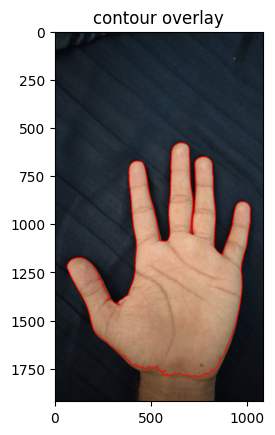

In [43]:
contours, _= cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
largest=max(contours, key=cv2.contourArea)
print("no of contours found = ", len(contours))
print("points in largest contour = ", len(largest))
img_with_contour=cv2.cvtColor(img_cropped, cv2.COLOR_BGR2RGB).copy()
cv2.drawContours(img_with_contour, [largest], -1, (255, 0,0), 3)
plt.imshow(img_with_contour)
plt.title("contour overlay")
plt.show()

In [44]:
points = largest.reshape(-1,2)
points[:, 1] = -points[:, 1]   # y-flip fix: image coords (y-down) -> Cartesian (y-up)

print("shape of points array: ", points.shape)
print("first 5 points:\n", points[:5])

shape of points array:  (6011, 2)
first 5 points:
 [[ 653 -579]
 [ 652 -580]
 [ 651 -580]
 [ 650 -580]
 [ 649 -580]]


In [45]:
def scale_to_workspace(points,workspace_size=1.5):
  points=points.astype(float)
  centroid=points.mean(axis=0)
  centered=points-centroid
  max_dist=np.max(np.linalg.norm(centered,axis=1))
  scaled=centered/max_dist * workspace_size
  return scaled

workspace_points=scale_to_workspace(points)

In [46]:
import numpy as np
def fk(theta1,theta2,l1,l2):
       x=l1*np.cos(theta1) + l2*np.cos(theta1+theta2)
       y=l1*np.sin(theta1)+ l2*np.sin(theta1+theta2)
       return x,y


In [1]:
import numpy as np
def ik(x,y,l1,l2):
  theta2=np.arccos((x**2+y**2-l1**2-l2**2)/(2*l1*l2))
  k1=l1+l2*np.cos(theta2)
  k2= l2*np.sin(theta2)
  theta1=np.atan2(y,x)-np.atan2(k2,k1)
  return theta1,theta2


In [48]:
test_points=[(1.0,1.0),(1.5,0.5),(0.5,1.2)]
for x,y in test_points:
  theta1,theta2=ik(x,y,1.0,1.0)
  x_check,y_check=fk(theta1,theta2,1.0,1.0)
  print("angles are:", theta1,theta2)
  print("fk values are: ", x_check,y_check)

angles are: 0.0 1.5707963267948966
fk values are:  1.0 1.0
angles are: -0.3373074814297668 1.318116071652818
fk values are:  1.5 0.5
angles are: 0.312793317025594 1.726423780139082
fk values are:  0.5 1.2


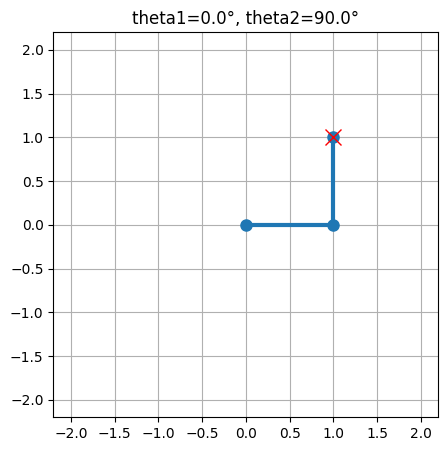

In [49]:
import matplotlib.pyplot as plt

def plot_arm(theta1, theta2, l1=1.0, l2=1.0, target=None):
    elbow_x = l1 * np.cos(theta1)
    elbow_y = l1 * np.sin(theta1)
    tip_x, tip_y = fk(theta1, theta2, l1, l2)

    plt.figure(figsize=(5,5))
    plt.plot([0, elbow_x, tip_x], [0, elbow_y, tip_y], 'o-', linewidth=3, markersize=8)
    if target:
        plt.plot(target[0], target[1], 'rx', markersize=12)
    plt.xlim(-2.2, 2.2)
    plt.ylim(-2.2, 2.2)
    plt.grid(True)
    plt.gca().set_aspect('equal')
    plt.title(f"theta1={np.degrees(theta1):.1f}°, theta2={np.degrees(theta2):.1f}°")
    plt.show()

# Test it
theta1, theta2 = ik(1.0, 1.0, 1.0, 1.0)
plot_arm(theta1, theta2, target=(1.0, 1.0))

In [50]:
def path_to_angles(points,l1=1.0,l2=1.0):
  angles = []
  used_points=[]
  skipped=0
  for x,y in points:
    cos_theta2=(x**2+y**2-l1**2-l2**2)/(2*l1*l2)
    if cos_theta2<-1 or cos_theta2>1:
      skipped+=1
      continue
    theta1,theta2=ik(x,y,l1,l2)
    angles.append((theta1,theta2))
    used_points.append((x,y))
  print("number of angle pairs: ", len(angles))
  print("number of points skipped: ", skipped)
  return angles, used_points
angle_path, used_points=path_to_angles(workspace_points)

number of angle pairs:  6011
number of points skipped:  0


In [51]:
print(workspace_points.shape)

(6011, 2)


In [52]:
print(len(workspace_points))
angle_path, used_points = path_to_angles(workspace_points)

6011
number of angle pairs:  6011
number of points skipped:  0


KeyboardInterrupt: 

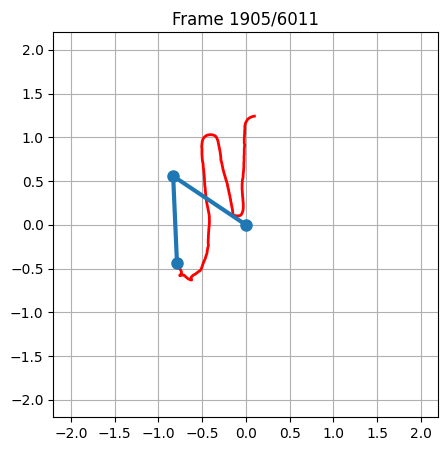

In [53]:
import matplotlib.animation as animation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(5,5))
traced_x=[]
traced_y=[]
def update(frame):
    ax.clear()
    theta1, theta2 = angle_path[frame]
    elbow_x = np.cos(theta1)
    elbow_y = np.sin(theta1)
    tip_x, tip_y = fk(theta1, theta2,l1=1.0,l2=1.0)

    traced_x.append(tip_x)
    traced_y.append(tip_y)

    ax.plot(traced_x, traced_y, 'r-', linewidth=2)
    ax.plot([0, elbow_x, tip_x], [0, elbow_y, tip_y], 'o-', linewidth=3, markersize=8)
    ax.set_xlim(-2.2, 2.2)
    ax.set_ylim(-2.2, 2.2)
    ax.grid(True)
    ax.set_aspect('equal')
    ax.set_title(f"Frame {frame}/{len(angle_path)}")

step = 5
frames_to_use = range(0, len(angle_path), step)

ani = animation.FuncAnimation(fig, update, frames=frames_to_use, interval=50)
HTML(ani.to_jshtml())
# did not complete this cell as taking too much time and memory. And the path simplification is exactly for cases like this where
# too much memory and space used

In [54]:
print(type(angle_path))
print(len(angle_path))
print(angle_path[0])
print(type(angle_path[0]))

<class 'list'>
6011
(np.float64(0.5936516234162831), np.float64(1.797617683080108))
<class 'tuple'>


In [55]:
errors=[]
for i, (x_org,y_org) in enumerate(used_points):
  theta1,theta2 = angle_path[i]
  x_traced, y_traced= fk(theta1, theta2, l1=1.0, l2=1.0)
  error=np.sqrt((x_org-x_traced)**2 + (y_org-y_traced)**2)
  errors.append(error)

errors=np.array(errors)
print("mean error:", errors.mean())
print("max error", errors.max())
print("min error", errors.min())

mean error: 1.8736496070447855e-16
max error 8.216072331155113e-16
min error 0.0


In [56]:
def auto_simplify(contour, min_points=15, max_points=500, max_iterations=20):
    perimeter = cv2.arcLength(contour, True)
    epsilon_low = 0.0001 * perimeter
    epsilon_high = 0.05 * perimeter

    for i in range(max_iterations):
        epsilon_mid = (epsilon_low + epsilon_high) / 2
        simplified = cv2.approxPolyDP(contour, epsilon_mid, True)
        n_points = len(simplified)

        if min_points <= n_points <= max_points:
            print(f"Found epsilon={epsilon_mid:.3f} giving {n_points} points after {i+1} iterations")
            return simplified, epsilon_mid
        elif n_points > max_points:
            epsilon_low = epsilon_mid   # too many points, need MORE simplification -> increase epsilon
        else:
            epsilon_high = epsilon_mid  # too few points, need LESS simplification -> decrease epsilon

    print(f"Did not converge after {max_iterations} iterations, returning best attempt: {n_points} points")
    return simplified, epsilon_mid

In [57]:
simplified_auto, epsilon_used = auto_simplify(largest, min_points=50, max_points=500)
print("Points:", len(simplified_auto))
print("Epsilon used:", epsilon_used)

Found epsilon=5.876 giving 89 points after 6 iterations
Points: 89
Epsilon used: 5.876272794551961


In [58]:
perimeter=cv2.arcLength(largest, True)
epsilon=0.01*perimeter
simplified=cv2.approxPolyDP(largest,epsilon,True)
print("original points: ", len(largest))
print("simplified points: ", len(simplified_auto))

original points:  6011
simplified points:  89


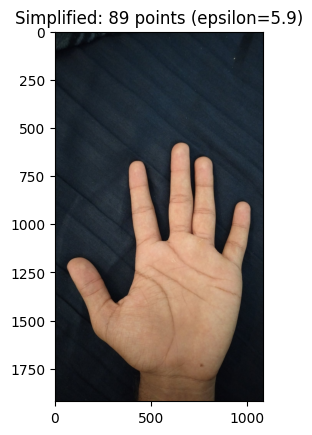

In [59]:
img_simplified=cv2.cvtColor(img_cropped, cv2.COLOR_BGR2RGB).copy()
cv2.drawContours(img_simplified, [simplified_auto], -1, (0,255,0), 3)
plt.imshow(img_simplified)
plt.title(f"Simplified: {len(simplified_auto)} points (epsilon={epsilon_used:.1f})")
plt.show()


In [64]:
points = simplified_auto.reshape(-1, 2)
points = points.astype(float)


workspace_points = scale_to_workspace(points)
angle_path, used_points = path_to_angles(workspace_points)

print("Points now:", len(workspace_points))
print("Angles now:", len(angle_path))

number of angle pairs:  89
number of points skipped:  0
Points now: 89
Angles now: 89


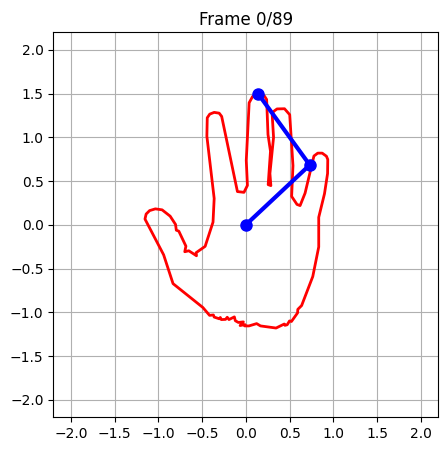

In [65]:
fig, ax = plt.subplots(figsize=(5,5))
traced_x = []
traced_y = []

def update(frame):
    ax.clear()
    theta1, theta2 = angle_path[frame]
    elbow_x = np.cos(theta1)
    elbow_y = np.sin(theta1)
    tip_x, tip_y = fk(theta1, theta2, l1=1.0, l2=1.0)
    traced_x.append(tip_x)
    traced_y.append(tip_y)
    ax.plot(traced_x, traced_y, 'r-', linewidth=2)
    ax.plot([0, elbow_x, tip_x], [0, elbow_y, tip_y], 'o-', linewidth=3, markersize=8, color='blue')
    ax.set_xlim(-2.2, 2.2)
    ax.set_ylim(-2.2, 2.2)
    ax.grid(True)
    ax.set_aspect('equal')
    ax.set_title(f"Frame {frame}/{len(angle_path)}")

frames_to_use = range(len(angle_path))  # use every single point, no step needed

ani = animation.FuncAnimation(fig, update, frames=frames_to_use, interval=200)
HTML(ani.to_jshtml())

In [66]:
def path_deviation(original_points, simplified_points):
    deviations = []
    for orig_pt in original_points:
        # distance from this original point to every simplified point
        dists = np.linalg.norm(simplified_points - orig_pt, axis=1)
        min_dist = dists.min()
        deviations.append(min_dist)
    return np.array(deviations)

# Compare original (scaled) points vs simplified (scaled) points
orig_scaled = scale_to_workspace(largest.reshape(-1, 2).astype(float))
simplified_scaled = scale_to_workspace(simplified.reshape(-1, 2).astype(float))

deviations = path_deviation(orig_scaled, simplified_scaled)
print("Mean deviation:", deviations.mean())
print("Max deviation:", deviations.max())

Mean deviation: 0.22115144025323627
Max deviation: 0.5449132958892411


In [67]:
def scale_with_params(points, centroid, max_dist, workspace_size=1.5):
    points = points.astype(float)
    centered = points - centroid
    scaled = centered / max_dist * workspace_size
    return scaled

# Compute scaling parameters ONCE, from the original full contour
orig_points = largest.reshape(-1, 2).astype(float)
centroid = orig_points.mean(axis=0)
centered = orig_points - centroid
max_dist = np.max(np.linalg.norm(centered, axis=1))

# Apply the SAME centroid and max_dist to both point sets
orig_scaled = scale_with_params(orig_points, centroid, max_dist)
simplified_points_raw = simplified.reshape(-1, 2).astype(float)
simplified_scaled = scale_with_params(simplified_points_raw, centroid, max_dist)

deviations = path_deviation(orig_scaled, simplified_scaled)
print("Mean deviation:", deviations.mean())
print("Max deviation:", deviations.max())

Mean deviation: 0.21893085037905766
Max deviation: 0.5240699855815708
